# 图 7-6　三个可跑的复杂系统实验与逐层叠加的综合模型

对应书稿第七章图 7-6。前几节的概念（涌现、自组织、标度律、临界）在这一节被真正跑一遍：

| 实验 | 对应概念 | 数据 |
|---|---|---|
| ① 谢林棋盘 | 涌现、临界 | 无外部数据（50×50 棋盘，密度 0.9） |
| ② 四类生成模型对照 | 小世界、无标度、生成机制非唯一性 | 本章出生—死亡网络：8,893 地点、54,275 条边（89,957 条非同城记录，往返合并前 58,117 条有向地点对） |
| ③ 渗流扫描 | 临界、巨组件 | 同上 |

**口径**：网络节点 = `fig1c_locations.csv` 的 9,448 个地点中出现于非同城出生—死亡记录的 8,893 个；
边 = 出生地—死亡地对（无向、按人次加权）。四个对照模型（随机图、配置模型、BA 优先连接、空间邻近图）
与实测网络同规模。

**输出**：`figures/fig7_6_notebook.png` + `results_schelling_notebook.json` / `results_complex_notebook.json`。

In [1]:
import json, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

HERE = Path.cwd()
RNG_SEED = 20261021


def gamma_of(G, kmin=3):
    """尾度 CCDF 的双对数斜率（γ − 1），k>=kmin。"""
    deg = np.array([d for _, d in G.degree()])
    k = np.sort(deg[deg >= kmin])
    if len(k) < 50:
        return float("nan")
    ccdf = 1.0 - np.arange(len(k)) / len(k)
    return float(1 - np.polyfit(np.log(k), np.log(ccdf), 1)[0])


def metrics(G, sources=300, cutoff=12, seed=1):
    n, m = G.number_of_nodes(), G.number_of_edges()
    comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    deg = np.array([d for _, d in G.degree()])
    rng = np.random.default_rng(seed)
    ns = list(rng.choice(list(G.nodes()), min(sources, n), replace=False))
    L = []
    for s in ns:
        L += [v for v in nx.single_source_shortest_path_length(G, s, cutoff=cutoff).values() if v > 0]
    top = np.sort(deg)[::-1]
    k1 = max(1, int(round(n * 0.01)))
    return {"n": n, "m": m, "gamma": gamma_of(G), "cc": float(nx.average_clustering(G)),
            "path": float(np.mean(L)) if L else float("nan"), "giant": comps[0] / n,
            "maxdeg": int(deg.max()), "top1pct_share": float(top[:k1].sum() / (2 * m))}


def spatial_graph(coord, nodes, k=12):
    from sklearn.neighbors import BallTree
    nodes = [x for x in nodes if x in coord.index]
    xy = np.radians(coord.loc[nodes, ["lat", "lon"]].values)
    tree = BallTree(xy, metric="haversine")
    _, ind = tree.query(xy, k=k + 1)
    G = nx.Graph()
    G.add_nodes_from(nodes)
    for i, nb in enumerate(ind):
        for j in nb[1:]:
            G.add_edge(nodes[i], nodes[j])
    return G

print("helpers ready")

/Users/socrates/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/socrates/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


helpers ready


## 实验①　谢林棋盘：温和偏好如何涌现出分隔

50×50 格子，90% 被两类主体各占一半；每个主体要求**同类邻居占比不低于容忍度 t**（8 邻域），
不满足就搬到随机空位，直到无人不满。指标为分隔指数 = 邻居中同类的平均比例（随机混合基准约 0.5）。
每档容忍度重复 5 次。局部增量更新（只重算移动点两处 3×3 邻域的计数），可跑到收敛。

In [2]:
def local_counts(g, i, j):
    n = g.shape[0]
    me = g[i, j]
    if me == 0:
        return 0, 0
    same = tot = 0
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            a, b = i + di, j + dj
            if 0 <= a < n and 0 <= b < n and g[a, b] > 0:
                tot += 1
                same += g[a, b] == me
    return same, tot


def neighbours_of(i, j, n):
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            a, b = i + di, j + dj
            if 0 <= a < n and 0 <= b < n:
                yield a, b


def schelling(n=50, density=0.9, tol=0.3, max_moves=200000, seed=0):
    rng = np.random.default_rng(seed)
    ncell = n * n
    g = np.zeros(ncell, dtype=np.int8)
    idx = rng.choice(ncell, int(ncell * density), replace=False)
    g[idx] = rng.integers(1, 3, int(ncell * density))
    g = g.reshape(n, n)
    same = np.zeros((n, n), dtype=np.int16)
    tot = np.zeros((n, n), dtype=np.int16)
    for i in range(n):
        for j in range(n):
            same[i, j], tot[i, j] = local_counts(g, i, j)

    def unhappy_mask():
        frac = np.where(tot > 0, same / np.maximum(tot, 1), 1.0)
        return (g > 0) & (tot > 0) & (frac < tol)

    moves = 0
    while moves < max_moves:
        uh = np.argwhere(unhappy_mask())
        if len(uh) == 0:
            break
        empty = np.argwhere(g == 0)
        if len(empty) == 0:
            break
        src = uh[rng.integers(0, len(uh))]
        dst = empty[rng.integers(0, len(empty))]
        g[dst[0], dst[1]] = g[src[0], src[1]]
        g[src[0], src[1]] = 0
        for (i, j) in set(neighbours_of(*src, n)) | set(neighbours_of(*dst, n)):
            same[i, j], tot[i, j] = local_counts(g, i, j)
        moves += 1
    frac = np.where(tot > 0, same / np.maximum(tot, 1), np.nan)
    return {"same": float(np.nanmean(frac)), "moves": moves,
            "converged": bool(unhappy_mask().sum() == 0)}, g.copy()


tols = [round(x, 2) for x in np.arange(0.10, 0.61, 0.05)]
rows = []
for t in tols:
    vals, mv, ok = [], [], []
    for rep in range(5):
        r, _ = schelling(tol=t, seed=200 + rep)
        vals.append(r["same"]); mv.append(r["moves"]); ok.append(r["converged"])
    rows.append({"tol": t, "mean": float(np.mean(vals)), "sd": float(np.std(vals)),
                 "moves": float(np.mean(mv)), "converged": int(sum(ok))})
sch = pd.DataFrame(rows)
print(sch.to_string(index=False,
      formatters={"mean": "{:.3f}".format, "sd": "{:.3f}".format, "moves": "{:.0f}".format}))

snaps = {}
for t in ("0.2", "0.3", "0.45"):
    r, g = schelling(tol=float(t), seed=7)
    snaps[t] = {"grid": g.tolist(), "same": r["same"], "moves": r["moves"], "converged": r["converged"]}
    print(f"快照 tol={t}  分隔指数={r['same']:.3f}  收敛={r['converged']}")

json.dump({"rows": rows, "snaps": snaps},
          open(HERE / "results_schelling_notebook.json", "w", encoding="utf-8"), ensure_ascii=False)

 tol  mean    sd moves  converged
0.10 0.514 0.004    25          5
0.15 0.558 0.005   142          5
0.20 0.569 0.006   179          5
0.25 0.578 0.009   222          5
0.30 0.752 0.011   912          5
0.35 0.767 0.009  1036          5
0.40 0.826 0.009  1461          5
0.45 0.875 0.008  1960          5
0.50 0.875 0.008  1960          5
0.55 0.934 0.004  3412          5
0.60 0.972 0.002  6179          5
快照 tol=0.2  分隔指数=0.573  收敛=True
快照 tol=0.3  分隔指数=0.754  收敛=True
快照 tol=0.45  分隔指数=0.894  收敛=True


## 实验②③　本章网络：四类生成模型对照与渗流扫描

同一张出生—死亡网络上，让四种生成规则各长一次，与实测对照四项指标：
度分布尾指数 γ（k≥3）、平均聚类系数、平均最短路径（300 个源点抽样，截断 12）、
最大 1% 节点持有的连接份额。渗流扫描按边权（共同流量）从高到低放回，观察巨组件何时出现。

In [3]:
locs = set(pd.read_csv(HERE / "fig1c_locations.csv")["loc"].astype(str).str.strip().str.lower())
df = pickle.load(open(HERE / "records_fixed.pkl", "rb"))
df["bl"] = df["BLocLabel"].astype(str).str.strip().str.lower()
df["dl"] = df["DLocLabel"].astype(str).str.strip().str.lower()
sub = df[df.bl.isin(locs) & df.dl.isin(locs) & (df.bl != df.dl)]
edges = sub.groupby(["bl", "dl"]).size().reset_index(name="w")
G = nx.Graph()
for u, v, w in edges.itertuples(index=False):
    if G.has_edge(u, v):
        G[u][v]["weight"] += w
    else:
        G.add_edge(u, v, weight=w)
coord = sub.groupby("bl")[["BLat", "BLon"]].median().rename(columns={"BLat": "lat", "BLon": "lon"})
print(f"记录 {len(sub)} 人次 | 有向地点对 {len(edges)} | 无向加权边 {G.number_of_edges()} | 节点 {G.number_of_nodes()}")

models = {"data": metrics(G)}
models["random"] = metrics(nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=11))
deg_seq = [d for _, d in G.degree()]
cm = nx.Graph(nx.configuration_model(deg_seq, seed=12))
cm.remove_edges_from(nx.selfloop_edges(cm))
models["config"] = metrics(cm)
m_ba = max(1, int(round(G.number_of_edges() / G.number_of_nodes())))
models["ba"] = metrics(nx.barabasi_albert_graph(G.number_of_nodes(), m_ba, seed=13))
models["spatial"] = metrics(spatial_graph(coord, list(G.nodes())))

cmp = pd.DataFrame(models).T
cmp.index = ["本章网络（实测）", "随机图", "配置模型", f"BA 优先连接 (m={m_ba})", "空间邻近图 (k=12)"]
print(cmp.round(3).to_string())

perc = []
for thr in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 50, 80, 120, 200]:
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from((u, v) for u, v, w in edges.itertuples(index=False) if w >= thr)
    comps = sorted((len(c) for c in nx.connected_components(H)), reverse=True)
    perc.append({"thr": thr, "edges": H.number_of_edges(), "giant": comps[0] / G.number_of_nodes(),
                 "k": 2 * H.number_of_edges() / G.number_of_nodes()})
print(pd.DataFrame(perc).round(3).to_string(index=False))

json.dump({"models": models, "percolation": perc, "ba_m": m_ba},
          open(HERE / "results_complex_notebook.json", "w", encoding="utf-8"), ensure_ascii=False)

记录 89957 人次 | 有向地点对 58117 | 无向加权边 54275 | 节点 8893
                    n        m  gamma     cc   path  giant  maxdeg  top1pct_share
本章网络（实测）       8893.0  54275.0  2.028  0.253  3.215  0.999  1459.0          0.239
随机图            8893.0  54275.0  3.678  0.002  3.902  1.000    27.0          0.018
配置模型           8893.0  51380.0  2.042  0.079  3.291  0.999   977.0          0.212
BA 优先连接 (m=6)  8893.0  53322.0  2.853  0.010  3.450  1.000   448.0          0.104
空间邻近图 (k=12)   8489.0  62724.0  7.198  0.610  8.418  0.998    25.0          0.016
 thr  edges  giant      k
   1  54275  0.999 12.206
   2   8671  0.382  1.950
   3   3830  0.207  0.861
   4   2339  0.141  0.526
   5   1612  0.107  0.363
   6   1216  0.083  0.273
   8    823  0.060  0.185
  10    588  0.044  0.132
  15    322  0.026  0.072
  20    218  0.018  0.049
  30    105  0.008  0.024
  50     42  0.003  0.009
  80     16  0.001  0.004
 120      4  0.000  0.001
 200      2  0.000  0.000


## 合并版图 7-6（A–F）

书稿图 7-6 现为六面板合并版：A 谢林棋盘、B 分隔指数突变、C 边距—聚类平面（融合生成模型对照与
逐层叠加轨迹）、D 渗流临界、E β 扫描、F θ 扫描。

- A、B、D 使用本 notebook 上文实跑的结果；
- C、E、F 使用书稿统一口径的预计算结果（`results_table73_unified.json`、`results_spatial_config.json`、
  `results_cc_constrained.json`）——其中的空间约束配置模型与空间—闭合综合模型由保持度序列的
  边交换蒙特卡洛采样得到（脚本 `38_spatial_config_mcmc.py`、`41_cc_constrained.py`），
  单次采样约需小时级机时，此处直接读入绘图。

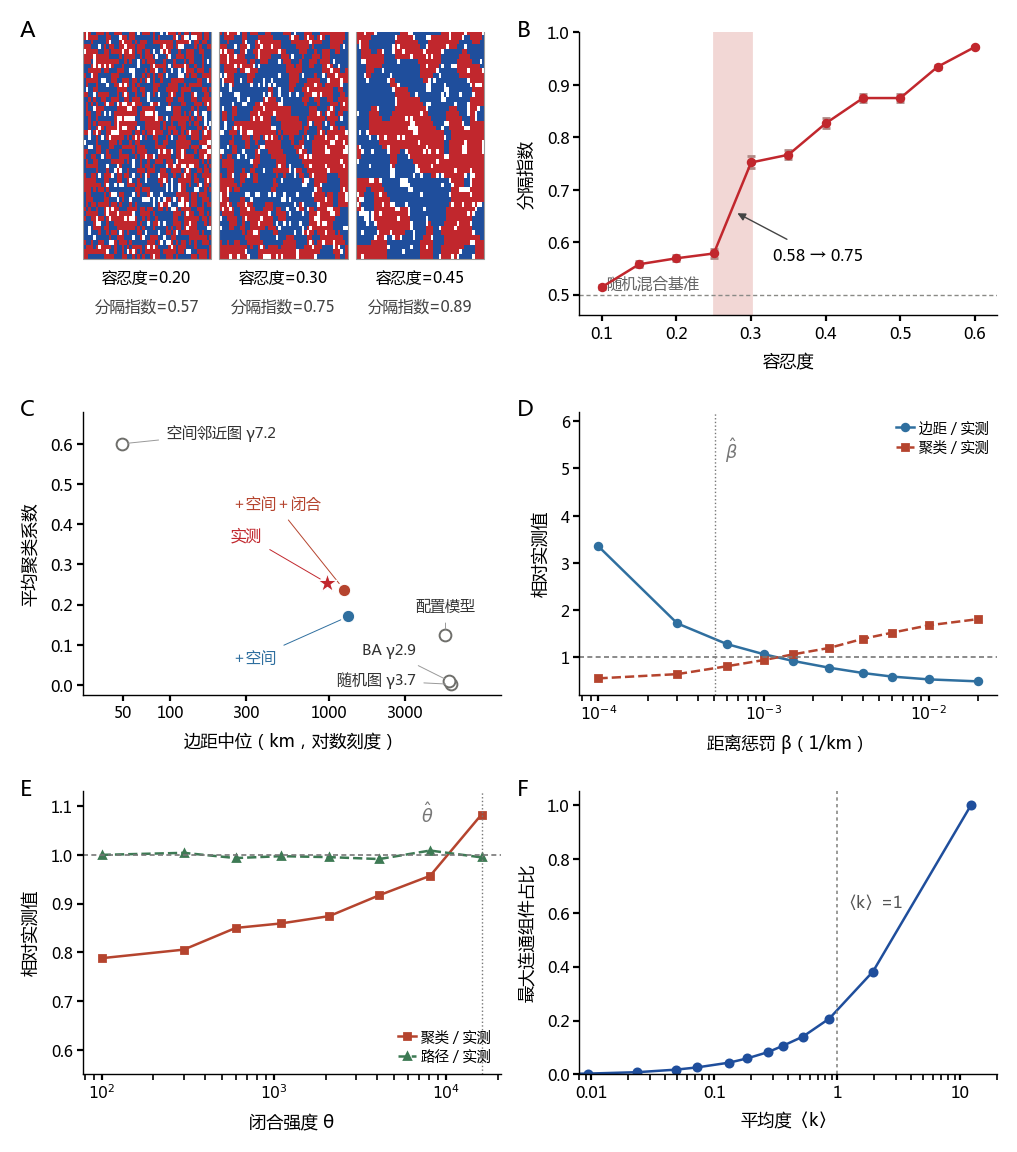

In [38]:
# 六面板合并图（与书稿图 7-6 同一版式：A-F）
plt.rcParams["font.family"] = ["SimSun", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 6.8
plt.rcParams["axes.linewidth"] = 0.5
CM = 1 / 2.54
C1, C2, CG = "#C1272D", "#1F4E9C", "#8A8A86"
C_BLUE, C_RED, C_GREEN, C_GRAY = "#2f6f9f", "#b5442e", "#3d7a54", "#777777"

T73 = json.load(open(HERE / "results_table73_unified.json", encoding="utf-8"))
SCJ = json.load(open(HERE / "results_spatial_config.json", encoding="utf-8"))
CCJ = json.load(open(HERE / "results_cc_constrained.json", encoding="utf-8"))
obs = T73["data"]

fig = plt.figure(figsize=(13.2 * CM, 15.3 * CM), dpi = 200)

# ---- A 三档快照
axA = fig.add_axes([0.062, 0.705, 0.402, 0.235]); axA.set_xlim(0, 3.06); axA.set_ylim(0, 1.0); axA.axis("off")
# axA.text(-0.03, 1.02, "A", transform=axA.transAxes, fontsize=8, fontweight="bold", va="top")
axA.text(-0.15, 1.045, "A", transform=axA.transAxes, fontsize=8, fontweight="bold", va="top")
# axA.text(1.53, 1.09, "谢林棋盘", ha="center", va="center", fontsize=6)
labs = {"0.2": "0.20", "0.3": "0.30", "0.45": "0.45"}
for k, key in enumerate(("0.2", "0.3", "0.45")):
    g = np.array(snaps[key]["grid"])
    rgb = np.ones(g.shape + (3,))
    rgb[g == 1] = matplotlib.colors.to_rgb(C1)
    rgb[g == 2] = matplotlib.colors.to_rgb(C2)
    axA.imshow(rgb, extent=[k, k + 0.94, 0.20, 1.04], aspect="auto", interpolation="nearest")
    axA.add_patch(plt.Rectangle((k, 0.20), 0.94, 0.84, fill=False, lw=0.4, ec="#999999"))
    axA.text(k + 0.47, 0.13, f"容忍度={float(labs[key]):.2f}" , ha="center", va="center", fontsize=5.6)
    axA.text(k + 0.47, 0.03, f"分隔指数={snaps[key]['same']:.2f}" , ha="center", va="center", fontsize=5.6, color="#444444")

# ---- B 分隔指数
axB = fig.add_axes([0.540, 0.705, 0.402, 0.235])
x = np.array([r["tol"] for r in rows]); y = np.array([r["mean"] for r in rows]); sd = np.array([r["sd"] for r in rows])
axB.axvspan(0.25, 0.30, color="#F2D7D5", zorder=0)
axB.errorbar(x, y, yerr=sd, fmt="o-", ms=2.4, lw=0.9, color=C1, ecolor="#B08A86", elinewidth=0.5, capsize=1.5, zorder=3)
axB.axhline(0.5, color=CG, lw=0.5, ls=(0, (3, 2)))
axB.text(0.105, 0.512, "随机混合基准", fontsize=5.6, color="#666666")
axB.annotate("0.58 → 0.75", xy=(0.275, 0.66), xytext=(0.33, 0.565), fontsize=5.8,
             arrowprops=dict(arrowstyle="-|>", lw=0.5, color="#444444"))
axB.set_xlabel("容忍度", fontsize=6.2); axB.set_ylabel("分隔指数", fontsize=6.2)
axB.set_xlim(0.07, 0.63); axB.set_ylim(0.46, 1.0)
axB.tick_params(labelsize=5.8, length=2, pad=1.5)
for s in ("top", "right"): axB.spines[s].set_visible(False)
axB.text(-0.15, 1.045, "B", transform=axB.transAxes, fontsize=8, fontweight="bold", va="top")

# ---- C 边距—聚类平面（融合面板）
axC = fig.add_axes([0.062, 0.390, 0.402, 0.235]); axC.set_xscale("log")
gen = [("random", "随机图 γ3.7", (3500, 0.0), "right"),
       ("ba", "BA γ2.9", (3500, 0.075), "right"),
       ("config", "配置模型", (5403, 0.185), "center"),
       ("spatial", "空间邻近图 γ7.2", (95, 0.615), "left")]
for key, lab, (tx, ty), ha in gen:
    v = T73[key]
    axC.scatter(v["med_dist"], v["cc"], s=18, facecolor="white", edgecolor="#6E6E6A", lw=0.7, zorder=3)
    axC.annotate(lab, (v["med_dist"], v["cc"]), xytext=(tx, ty), fontsize=5.4, color="#333333", ha=ha,
                 arrowprops=dict(arrowstyle="-", lw=0.35, color="#999999", shrinkA=1, shrinkB=2))
axC.scatter(T73["spatial2"]["med_dist"], T73["spatial2"]["cc"], s=20, color=C_BLUE, zorder=5, edgecolor="white", linewidth=0.4)
axC.scatter(T73["three"]["med_dist"], T73["three"]["cc"], s=20, color=C_RED, zorder=5, edgecolor="white", linewidth=0.4)
axC.scatter(obs["med_dist"], obs["cc"], s=52, marker="*", color=C1, zorder=6, edgecolor="white", linewidth=0.4)
axC.annotate("＋空间", (T73["spatial2"]["med_dist"], T73["spatial2"]["cc"]), xytext=(240, 0.055), fontsize=5.4, color=C_BLUE, ha="left",
             arrowprops=dict(arrowstyle="-", lw=0.35, color=C_BLUE, shrinkA=1, shrinkB=3))
axC.annotate("＋空间＋闭合", (T73["three"]["med_dist"], T73["three"]["cc"]), xytext=(240, 0.440), fontsize=5.4, color=C_RED, ha="left",
             arrowprops=dict(arrowstyle="-", lw=0.35, color=C_RED, shrinkA=1, shrinkB=3))
axC.annotate("实测", (obs["med_dist"], obs["cc"]), xytext=(240, 0.360), fontsize=5.6, color=C1, ha="left",
             arrowprops=dict(arrowstyle="-", lw=0.35, color=C1, shrinkA=1, shrinkB=3))
axC.set_xlabel("边距中位（km，对数刻度）", fontsize=6.2); axC.set_ylabel("平均聚类系数", fontsize=6.2)
axC.set_xlim(28, 12000); axC.set_ylim(-0.025, 0.68)
axC.set_xticks([50, 100, 300, 1000, 3000]); axC.set_xticklabels(["50", "100", "300", "1000", "3000"], fontsize=5.6)
axC.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axC.xaxis.set_minor_locator(plt.FixedLocator([]))
axC.tick_params(axis="y", labelsize=5.8, length=2, pad=1.5); axC.tick_params(axis="x", length=2, pad=1.5)
for s in ("top", "right"): axC.spines[s].set_visible(False)
axC.text(-0.15, 1.045, "C", transform=axC.transAxes, fontsize=8, fontweight="bold", va="top")

# ---- D 渗流
axF = fig.add_axes([0.540, 0.075, 0.402, 0.235])
pg = [r for r in perc if r["k"] > 0]
axF.plot([r["k"] for r in pg], [r["giant"] for r in pg], "o-", ms=2.6, lw=0.9, color=C2)
axF.axvline(1.0, color=CG, lw=0.6, ls=(0, (2, 2)))
axF.text(1.06, 0.62, "〈k〉=1", fontsize=5.8, color="#555555")
axF.set_xscale("log")
axF.set_xticks([0.01, 0.1, 1, 10]); axF.set_xticklabels(["0.01", "0.1", "1", "10"])
axF.set_xlabel("平均度〈k〉", fontsize=6.2); axF.set_ylabel("最大连通组件占比", fontsize=6.2)
axF.set_ylim(0, 1.05); axF.set_xlim(0.008, 20)
axF.tick_params(labelsize=5.8, length=2, pad=1.5)
for s in ("top", "right"): axF.spines[s].set_visible(False)
axF.text(-0.15, 1.045, "F", transform=axF.transAxes, fontsize=8, fontweight="bold", va="top")

# ---- E β 扫描
axD = fig.add_axes([0.540, 0.390, 0.402, 0.235])
sw = [r for r in SCJ["sweep"] if r["beta"] > 0]
b = np.array([r["beta"] for r in sw])
nd = np.array([r["median_edge_dist"] for r in sw]) / obs["med_dist"]
nc = np.array([r["cc"] for r in sw]) / obs["cc"]
axD.semilogx(b, nd, "o-", color=C_BLUE, ms=2.4, lw=0.9, label="边距 / 实测")
axD.semilogx(b, nc, "s--", color=C_RED, ms=2.2, lw=0.9, label="聚类 / 实测")
axD.axhline(1.0, color=C_GRAY, lw=0.6, ls=(0, (3, 2)))
axD.axvline(SCJ["beta_hat"], color=C_GRAY, lw=0.5, ls=":")
axD.text(SCJ["beta_hat"] * 1.15, 5.2, r"$\hat{\beta}$", fontsize=6.4, color=C_GRAY)
axD.set_xticks([1e-4, 1e-3, 1e-2]); axD.set_xticklabels([r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$"], fontsize=5.6)
axD.set_xlabel("距离惩罚 β（1/km）", fontsize=6.2); axD.set_ylabel("相对实测值", fontsize=6.2)
axD.set_ylim(0.2, 6.2)
axD.tick_params(axis="y", labelsize=5.6, length=2, pad=1.5); axD.tick_params(axis="x", length=2, pad=1.5)
for s in ("top", "right"): axD.spines[s].set_visible(False)
axD.legend(fontsize=5.0, frameon=False, loc="upper right", handlelength=1.3, handletextpad=0.4,
           borderaxespad=0.2, labelspacing=0.25)
axD.text(-0.15, 1.045, "D", transform=axD.transAxes, fontsize=8, fontweight="bold", va="top")

# ---- F θ 扫描
axE = fig.add_axes([0.062, 0.075, 0.402, 0.235])
sw2 = CCJ["sweep"]
th = np.array([r["theta_c"] for r in sw2])
nc2 = np.array([r["cc"] for r in sw2]) / obs["cc"]
np2 = np.array([r["path"] for r in sw2]) / obs["path"]
xx = th + 100
axE.semilogx(xx, nc2, "s-", color=C_RED, ms=2.4, lw=0.9, label="聚类 / 实测")
axE.semilogx(xx, np2, "^--", color=C_GREEN, ms=2.2, lw=0.9, label="路径 / 实测")
axE.axhline(1.0, color=C_GRAY, lw=0.6, ls=(0, (3, 2)))
axE.axvline(CCJ["theta_hat"] + 100, color=C_GRAY, lw=0.5, ls=":")
axE.text(CCJ["theta_hat"] * 0.45, 1.065, r"$\hat{\theta}$", fontsize=6.4, color=C_GRAY)
axE.set_xticks([1e2, 1e3, 1e4]); axE.set_xticklabels([r"$10^{2}$", r"$10^{3}$", r"$10^{4}$"], fontsize=5.6)
axE.set_xlabel("闭合强度 θ", fontsize=6.2); axE.set_ylabel("相对实测值", fontsize=6.2)
axE.set_ylim(0.55, 1.13)
axE.tick_params(axis="y", labelsize=5.6, length=2, pad=1.5); axE.tick_params(axis="x", length=2, pad=1.5)
for s in ("top", "right"): axE.spines[s].set_visible(False)
axE.legend(fontsize=5.0, frameon=False, loc="lower right", handlelength=1.3, handletextpad=0.4,
           borderaxespad=0.3, labelspacing=0.25)
axE.text(-0.15, 1.045, "E", transform=axE.transAxes, fontsize=8, fontweight="bold", va="top")
plt.show()

In [39]:
out = HERE / "figures" / "fig7_6_complex_models_notebook.pdf"
fig.savefig(out, facecolor="white")
print("saved", out)

saved /Users/socrates/同步空间/Research/结构建模书稿章节/output/schich-repro/figures/fig7_6_complex_models_notebook.pdf
